In [12]:
#TP 3 n-body problem

#Imports

import numpy as np
import matplotlib.pyplot as plt
import random as rd 
%matplotlib ipympl




In [ ]:
# Echauffement: le broadcasting 

a = np.array([1, 2, 3])
print(a.shape)

print(a[:,None])
print(a[:,None].shape)
#Donc là ca renvoie le vecteur en colonne

print(a[None,:])
print(a[None,:].shape)

print(a[:,None]-a[None,:])
#On est censé obtenir une matrice 3x3
#En gros ca a fait le calcul :
#([[1,1,1],[2,2,2],[3,3,3]]-[[1,2,3],[1,2,3],[1,2,3]])

#L'élément (i,j) vaut donc a[i]-a[j]

b=np.array([[1,2,3],[1,2,3]])
print(b[:,None,:])
print(b[:,:,None])
print(b[:,None,:]-b[:,:,None])

# On a b[:, None, :][i, j, k] = b[i, k]
#b[:, :, None][i, j, k] = b[i, j]
#donc (b[:, None, :]-b[:, :, None])[i, j, k]= b[i, k]-b[i, j]

(3,)
[[1]
 [2]
 [3]]
(3, 1)
[[1 2 3]]
(1, 3)
[[ 0 -1 -2]
 [ 1  0 -1]
 [ 2  1  0]]
[[[1 2 3]]

 [[1 2 3]]]
[[[1]
  [2]
  [3]]

 [[1]
  [2]
  [3]]]
[[[ 0  1  2]
  [-1  0  1]
  [-2 -1  0]]

 [[ 0  1  2]
  [-1  0  1]
  [-2 -1  0]]]


In [29]:
#Initialisation aléatoire 


# les bornes pour le tirage au sort initial
mass_max = 3.
    
x_min, x_max = -10., 10.
y_min, y_max = -10., 10.

speed_max = 1.


#Il faut donner à low et high 
# une forme broadcastable vers (2, N).
#On peut donc leur donner la forme (2,1)
def init_problem(N):
  
    masses = np.random.uniform(0.1, mass_max,N)

    positions = np.random.uniform(
        np.array([[x_min], [y_min]]),
        np.array([[x_max], [y_max]]),
        (2, N) )


    speeds = np.random.uniform(
    np.array([[-speed_max],[-speed_max]]),
    np.array([[speed_max],[speed_max]]),
    (2, N))
    
    return masses, positions, speeds

masses, positions, speeds = init_problem(10)

try:
    assert masses.shape == (10,) and positions.shape == speeds.shape == (2, 10)
    print("OK")
except:
    print("KO")





OK


In [25]:
# Initialisation reproductible 

def init3():
    # first element is sun-like: heavy, at the center, and no speed
    masses = np.array([3, 1, 1], dtype=float)
    positions = np.array([
        [0, 5, -5], 
        [0, 1, -1]], dtype=float)
    speeds = np.array([
        [0, -1, 1], 
        [0, 0, 0]], dtype=float)
    return masses, positions, speeds

In [ ]:
# Les forces 

def forces(masses,positions,G=1.0):
    
    
    diff=positions[:,None,:]-positions[:,:,None]
    # de tel sorte que diff[:, i, j]= rj-ri

    # pour passer aux distances ||r_j - r_i||
    distance = np.linalg.norm(diff, axis=0)
    # shape de (N, N)

    #Éviter la division par zéro pour i == j
    #on peut remplir la diagonale de 1 car dans tous les cas
    #le numérateur vaudra 0 si i=j
    np.fill_diagonal(distance, 1)

    #Produits m_i * m_j pour tous les couples
    #On fait ainsi un produit terme à terme
    mass_product = masses[:, None] * masses[None, :]
    # shape de (N, N)

    #Coefficient scalaire G m_i m_j / distance^3
    coeff = G * mass_product / distance**3
    # shape de (N, N)

    # Multiplier chaque vecteur diff[:, i, j]
    # par son coefficient coeff[i, j]
    force = diff * coeff[None, :, :]
    # shape de (2, N, N)

    # Finalement on somme sur j :
    total_force = np.sum(force, axis=2)
    # shape de (2, N)

    return total_force
    
masses, positions, speeds = init3()
f = forces(masses, positions)


np.all(np.isclose(f, np.array([
     [ 0.        , -0.12257258,  0.12257258],
   [ 0.        , -0.02451452,  0.02451452]])))








np.True_

In [36]:
# Le simulateur 

def simulate(masses,positions,speeds,dt=0.1,nb_steps=100):
    
    #On créée le tableau vide grâce à positions
    dim, N = positions.shape
    resultat = np.empty((nb_steps, dim, N))
    
    #On rentre la position initiale 
    resultat[0] = positions
    
    #On construit une boucle qui calcule à partir des forces
    #l'accélération puis à partir de celle ci la vitesse
    #et cette vitesse nous donne la prochaine position
    for k in range(1,nb_steps):

        F = forces(masses, positions)
        
        #comme masse fait du (N,) alors numpy
        #le lit en (1,N) puis pour l'aligner avec (2,N)
        #numpy transforme le (1,N) en (2,N)
        acceleration = F / masses
        
        speeds = speeds + acceleration * dt
        positions = positions + speeds * dt

        resultat[k] = positions

    return resultat




# pour tester

SMALL_STEPS = 4

s = simulate(masses, positions, speeds, nb_steps=SMALL_STEPS)

try:
    if s.shape == (SMALL_STEPS, 2, 3):
        print("shape OK")
except Exception as exc:
    print(f"OOPS {type(exc)} {exc}")


# pour tester: should be true


positions1 = s[1]

np.all(np.isclose(positions1, np.array([
    [ 0.        ,  4.89877427, -4.89877427],
    [ 0.        ,  0.99975485, -0.99975485]
])))


shape OK


np.True_

In [37]:
# dessiner 

def draw(simulation, masses, colors=None, scale=10):

    nb_steps, dim, N = simulation.shape

    fig, ax = plt.subplots()

    for i in range(N):

        # Pour la trajectoire du corps i,
        #simulation[:, :, i] représente toutes 
        # les positions du corps i au cours du temps
        # sa forme est (nb_steps, 2) donc on transpose
        # pour avoir du (2, nb_steps)

        x, y = simulation[:, :, i].T

        # taille des points proportionnelle à la masse
        # et utilisant le coefficiant scale 
        size = scale * masses[i]

        # on ajoute la couleur selon si on a 
        # pris en argument une liste de couleurs ou non
        if colors is None:
            ax.scatter(x, y, s=size)
        else:
            ax.scatter(x, y, s=size, color=colors[i])

    ax.set_aspect("equal")

    return ax

In [38]:
# Un jeu de couleurs 

colors3 = np.array([
    [32, 32, 32],
    (228, 90, 146),
    (111, 0, 255),
]) / 255

<Axes: >

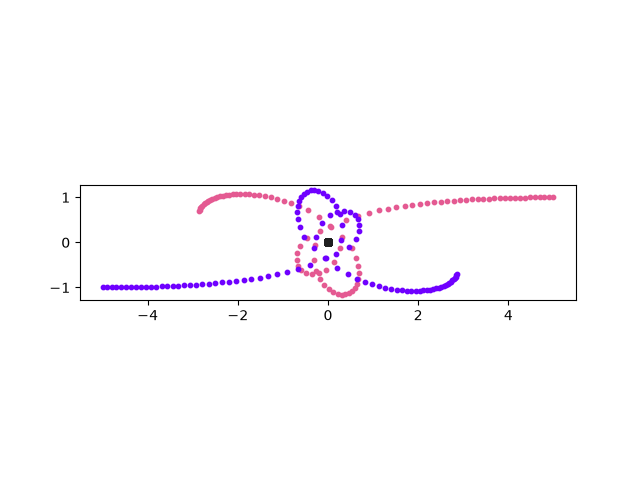

In [39]:
# On assemble tout 

masses, positions, speeds = init3()
draw(simulate(masses, positions, speeds), masses, colors3)


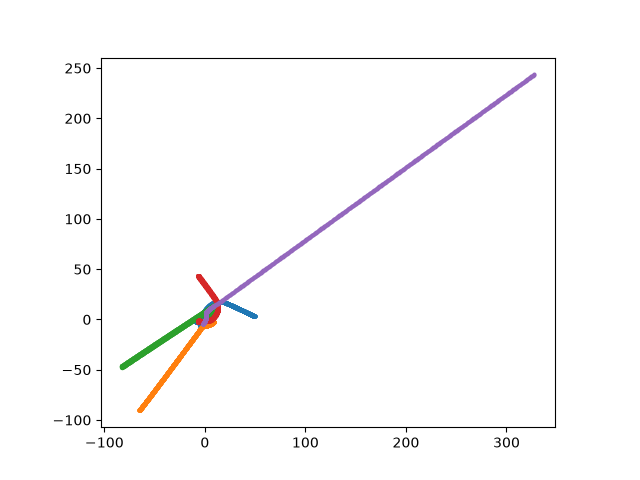

In [40]:
m5, p5, s5 = init_problem(5)
sim5 = simulate(m5, p5, s5, nb_steps=1000)
draw(sim5, m5, scale=3);
plt.savefig("random5.png")